In [5]:
from buoyancy_gradient import buo_coarse

import make_grid 
import build_coarse_grid 
import read_mitgcm 
import xarray as xr 
import numpy as np 
import gsw 
import importlib 
import coarsen_UVWTS 
from MITgcmutils import mds 
importlib.reload(coarsen_UVWTS) # force reload


In [6]:
def _k_name(da): # Find the vertical dim name that matches your data 
    for cand in ("k", "Z", "z", "lev", "k_c"): 
        if cand in da.dims: 
            return cand 
            # fallback: assume first dim is vertical (adjust if needed) 
    return da.dims[0]

def mld_integrals_for_MEI( dbdx_u: xr.DataArray, # (k,j,i_g) ∂b/∂x at U 
                           dbdy_v: xr.DataArray, # (k,j_g,i) ∂b/∂y at V 
                           kpphbl_C: xr.DataArray, # (j,i) ML depth at C 
                           ds_grid: xr.Dataset, 
                           grid, 
                           sigma_is_buoyancy: bool = True, 
                           g: float = 9.81, 
                           rho0: float = 1035.0, 
                         ): 
    # ---- 0) Standardize the vertical index 'k' everywhere ---- 
    RF = ds_grid["RF"] # (k_p1), negative downward , 50
    K = RF.sizes["k_p1"] - 1  # 49
    k_index = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    ku = _k_name(dbdx_u) 
    kv = _k_name(dbdy_v) 
    dbdx_u = (dbdx_u.rename({ku: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    dbdy_v = (dbdy_v.rename({kv: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    # Mixed-layer depth at faces 
    H_C = kpphbl_C.clip(min=0.0) 
    H_U = grid.interp(H_C, "X", to="left") # (j,i_g) 
    H_V = grid.interp(H_C, "Y", to="left") # (j_g,i) 
    # ---- 1) Interfaces as positive-down depths with SAME 'k' coords ---- 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_index) # 0 to Nr -1
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_index) # 1 to Nr
    # Broadcast to faces (will use positional matching now that 'k' is unified) 
    ztop_U = ztop1d.broadcast_like(dbdx_u) # (k,j,i_g) 
    zbot_U = zbot1d.broadcast_like(dbdx_u) 
    ztop_V = ztop1d.broadcast_like(dbdy_v) # (k,j_g,i) 
    zbot_V = zbot1d.broadcast_like(dbdy_v) 
    # Partial-cell thickness on faces 
    thkU = (zbot_U - ztop_U) * ds_grid["hFacW"] 
    thkV = (zbot_V - ztop_V) * ds_grid["hFacS"] 
    # ---- 2) Overlap thickness with [0, H_face] (no xr.minimum) ---- 
    H3U = H_U.broadcast_like(dbdx_u) 
    H3V = H_V.broadcast_like(dbdy_v) 
    # min(H, zbot) = where(H <= zbot, H, zbot) 
    minHU = xr.where(H3U <= zbot_U, H3U, zbot_U) 
    minHV = xr.where(H3V <= zbot_V, H3V, zbot_V) 
    wU = xr.where(H3U > ztop_U, minHU - ztop_U, 0.0) 
    wV = xr.where(H3V > ztop_V, minHV - ztop_V, 0.0) 
    # clip and enforce partial thickness 
    wU = xr.where(wU > 0, xr.where(wU < thkU, wU, thkU), 0.0) 
    wV = xr.where(wV > 0, xr.where(wV < thkV, wV, thkV), 0.0) 
    # ---- 3) Integrals over 0..H (∑ sigma * dzLoc) ---- 
    intX = (dbdx_u.fillna(0.0) * wU).sum("k") # (j,i_g) 
    intY = (dbdy_v.fillna(0.0) * wV).sum("k") # (j_g,i) 
    # ---- 4) Convert if sigma are density-gradients (yours are buoyancy-gradients) ---- 
    if sigma_is_buoyancy: 
        dBuoyX_Hu, dBuoyY_Hv = intX, intY 
        out_units = "s^-2 m" 
    else: 
        fac = -g / rho0 
        dBuoyX_Hu, dBuoyY_Hv = fac * intX, fac * intY 
        out_units = "kg m^-4 s^-2" 
    # Optional: mask dry faces 
    wetU = (ds_grid["hFacW"] > 0).any("k") 
    wetV = (ds_grid["hFacS"] > 0).any("k") 
    dBuoyX_Hu = dBuoyX_Hu.where(wetU) 
    dBuoyY_Hv = dBuoyY_Hv.where(wetV) 
    dBuoyX_Hu.name, dBuoyY_Hv.name = "dBuoyX_Hu", "dBuoyY_Hv" 
    for da in (dBuoyX_Hu, dBuoyY_Hv): 
        da.attrs["long_name"] = "ML integral of horizontal buoyancy gradient" 
        da.attrs["units"] = out_units 
    return dBuoyX_Hu, dBuoyY_Hv

In [7]:
import numpy as np 
import xarray as xr 
def compute_Lf_MEI( dBuoyX_Hu: xr.DataArray, # (j, i_g) 
                    dBuoyY_Hv: xr.DataArray, # (j_g, i) 
                    b: xr.DataArray, # (k, j, i) buoyancy at C 
                    H_C: xr.DataArray, # (j, i) ML depth at C 
                    f_eff_C: xr.DataArray, # (j, i) 
                    ds_grid: xr.Dataset, 
                    grid, 
                    g: float = 9.81, 
                    rho0: float = 1035.0, 
                    LfMin: float = 1000.0, ): 
    # --- A) Standardize vertical coord 'k' everywhere ----------------------- 
    RF = ds_grid["RF"] # (k_p1) 
    K = RF.sizes["k_p1"] - 1 
    k_idx = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    def to_k(da): 
        # rename vertical dim to 'k' if needed, then assign common index 
        for cand in ("k", "Z", "z", "lev", "k_c"): 
            if cand in da.dims: 
                if cand != "k": 
                    da = da.rename({cand: "k"}) 
                break 
        if "k" in da.dims: 
                da = da.assign_coords(k=k_idx).reset_coords(drop=True) 
        return da 
    b = to_k(b) 
    hFacC = to_k(ds_grid["hFacC"]) # (k,j,i) with unified k 
    # (dBuoyX_Hu, dBuoyY_Hv, H_C, f_eff_C are 2D—no k to fix) 
    # interfaces as positive-down depths with SAME 'k' coords 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_idx) 
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_idx) 
    ztop = ztop1d.broadcast_like(b) 
    zbot = zbot1d.broadcast_like(b) 
    # --- 1) MsqH at centers from face integrals averaged to C --------------- 
    dBx_C = grid.interp(dBuoyX_Hu, 'X') # U->C 
    dBy_C = grid.interp(dBuoyY_Hv, 'Y') # V->C 
    MsqH = np.sqrt(0.25*(dBx_C**2 + dBy_C**2)) # s^-2 m 
    # --- 2) NHmixLay at C via ML overlap (honor partial cells) -------------- 
    thkC = (zbot - ztop) * hFacC # partial thickness 
    H3C = H_C.assign_coords().broadcast_like(b) # (k,j,i) with unified k 
    # min(H,zbot) without xr.minimum (avoids version issues) 
    minHC = xr.where(H3C <= zbot, H3C, zbot) 
    wC = xr.where(H3C > ztop, minHC - ztop, 0.0) 
    wC = xr.where(wC > 0, xr.where(wC < thkC, wC, thkC), 0.0) 
    # ∂b/∂z at C using interface spacing (downward-positive dz) 
    db = b - b.shift(k=1) 
    dz = (ztop - ztop.shift(k=1)) 
    sigmaR = (db / dz).where(dz.notnull()) 
    sigmaR_pos = xr.where(sigmaR < 0.0, -sigmaR, 0.0) 
    NH_term = (sigmaR_pos * wC).sum("k") # units: s^-2 * m 
    NHmixLay = np.sqrt(NH_term * H_C.clip(min=0.0)).fillna(0.0) 
    # --- 3) Lf at centers --------------------------------------------------- 
    fC = xr.where(f_eff_C > 0, f_eff_C, np.nan) 
    cand1 = MsqH / (fC**2) # m 
    cand2 = NHmixLay / fC # m 
    Lf_center = xr.ufuncs.maximum( xr.ufuncs.maximum(cand1.fillna(0.0), cand2.fillna(0.0)), LfMin ).rename("Lf") 
    Lf_center.attrs.update(long_name="MEI length scale at centers", units="m") 
    # --- 4) centers -> faces for streamfunction denominators ---------------- 
    Lf_U = grid.interp(Lf_center, 'X', to='left') # C->U 
    Lf_V = grid.interp(Lf_center, 'Y', to='left') # C->V 
    Lf_U.name, Lf_V.name = "Lf_U", "Lf_V" 
    return Lf_center, Lf_U, Lf_V

In [18]:
# modules 
import read_mitgcm 
import coarsen_UVWTS 
import build_coarse_grid 
import make_grid
import numpy as np 
import xarray as xr 
from MITgcmutils import mds 
import mld_avg

# ---------------------------- parameters -------------------------------------
t = 4945536

box_i = box_j = 10 
# ---------------------------- MITgcm Path ------------------------------------- 
path_scratch = '/scratch/jczhang/' 
path_ds = 'data_5km/var/' 
path_MITgcm = 'MITgcm_5km/MITgcm/verification/tutorial_reentrant_channel/run/' 
grid_dir = path_scratch + path_MITgcm 
# ---------------------------- grid ------------------------------------- 
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir) 
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i) 
grid = make_grid.make_grid_periodic_x(ds_coarse) 
# ---------------------------- Ce, ds ------------------------------------- 
# efficiency coefficient Ce 
C_e = 0.03 
# hard upper cap - useless for my case, since dx < 111 km 
submeso_Lmax = 111000 # m 
# delta_s: local coarse model gridscale dimension 
delta_sx = ds_coarse["DXC"].clip(max=submeso_Lmax) # (j, i_g) 
delta_sy = ds_coarse["DYC"].clip(max=submeso_Lmax) # (j_g, i) 
# ---------------------------- mixed layer depth ------------------------------------ 
# mixed layer depth 
diagMXL = mds.rdmds(path_scratch + path_MITgcm + 'Diags/' +'DiagMXL_2d', t) 
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl") 
kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine, box_j, box_i) 
H_U = grid.interp(kpphbl_coarse, 'X', to='left') # (j, i_g) 
H_V = grid.interp(kpphbl_coarse, 'Y', to='left') # (j_g, i) 
# ---------------------------- buoyancy gradient and buoyancy ------------------------------------- 
T = read_mitgcm._ocean_var(grid_dir, "T", t, ("k","j","i")) 
T_coarse = coarsen_UVWTS.coarse_field("T", T, ds_fine, box_j, box_i) 
S = read_mitgcm._ocean_var(grid_dir, "S", t, ("k","j","i")) 
S_coarse = coarsen_UVWTS.coarse_field("S", S, ds_fine, box_j, box_i) 
Eta = read_mitgcm._ocean_var(grid_dir, "Eta", t, ("j","i")) 
Eta_coarse = coarsen_UVWTS.coarse_field("Eta", Eta, ds_fine, box_j, box_i) 
ds_ocean = xr.Dataset(dict(T=T, S=S, Eta=Eta)) 
ds_ocean_c = xr.Dataset(dict(T=T_coarse, S=S_coarse, Eta=Eta_coarse)) 
b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill") 
# integral over mixed layer 
dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI( dBdx_u, dBdy_V, kpphbl_coarse, ds_coarse, grid, sigma_is_buoyancy=True ) 
# ---------------------------- coriolis and tau------------------------------------- 
f0 = -1.363e-4 # s^-1 
beta = 1.313e-11 # s^-1 m^-1 
subMeso_invTau = 1.6e-6 
YC_da = xr.DataArray(ds_coarse["YC"], dims=('j','i')) 
y_ref = float(YC_da.mean()) 
f = (f0 + beta*(YC_da - y_ref)) # (j,i), s^-1 
f_eff = np.hypot(f, subMeso_invTau) 
f_U = grid.interp(f_eff, 'X', to='left') # (j,i_g) 
f_V = grid.interp(f_eff, 'Y', to='left') # (j_g,i) 
# ---------------------------- Lf = max(M/f, NH/|f|, Lf_min)------------------------------------- 
Lf_center, Lf_U, Lf_V = compute_Lf_MEI(dBuoyX_Hu=dBuoyX_Hu, dBuoyY_Hv=dBuoyY_Hv, b=b, H_C=kpphbl_coarse.clip(min=0.0), f_eff_C=f_eff, ds_grid=ds_coarse, grid=grid, LfMin=1000.0 ) 
# ---------------------------- mu(z)------------------------------------- 
# RF is negative downward (k_p1 interfaces); use it directly. 
rF = ds_coarse["RF"].rename(k_p1="k") # (k) ≤ 0 
rF_U = rF.broadcast_like(dBdx_u) # (k,j,i_g) 
rF_V = rF.broadcast_like(dBdy_V) # (k,j_g,i) 
# Mixed-layer depths on faces (positive) 
H_U = grid.interp(kpphbl_coarse.clip(min=0.0), 'X', to='left') 
H_V = grid.interp(kpphbl_coarse.clip(min=0.0), 'Y', to='left') 
# z2H must be negative inside the ML: [-2, 0] 
z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0) 
z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0) 
def mu_from(z2H): 
    q = (1.0 + z2H)**2 
    mu = (1.0 - q) * (1.0 + (5.0/21.0)*q) 
    return xr.where(mu > 0.0, mu, 0.0) 
muU = mu_from(z2H_U) # (k,j,i_g) 
muV = mu_from(z2H_V) # (k,j_g,i) 
# --- gridscale caps at faces (MIN(dx, Lmax), MIN(dy, Lmax)) --- 
dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax) # already (j, i_g) 
dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax) # already (j_g, i) 
# --- 2D streamfunction amplitudes at faces (depth-integrated) --- 
# Use 1/Lf_* and 1/f_* because Lf_U, Lf_V, f_U, f_V are already neighbor-averaged to faces 
_dBuoyY_Hu = grid.interp(dBuoyY_Hv, 'X', to='left')
_dBuoyY_Hu = -grid.interp(_dBuoyY_Hu, 'Y', to='center')
_dBuoyX_Hv = grid.interp(dBuoyX_Hu, 'Y', to='left')
_dBuoyX_Hv = -grid.interp(_dBuoyX_Hv, 'X', to='center')

PsiU0 = (-C_e * _dBuoyY_Hu * H_U * dx_cap_U * (1.0 / Lf_U) * (1.0 / f_U)).fillna(0.0) # (j,i_g) 
PsiV0 = (-C_e * _dBuoyX_Hv * H_V * dy_cap_V * (1.0 / Lf_V) * (1.0 / f_V)).fillna(0.0) # (j_g,i) 
PsiU0.name, PsiV0.name = "PsiU0", "PsiV0" 
# --- 3D streamfunctions using mu(z/H) --- 
muU_ = muU.transpose('k','j','i_g') # ensure consistent order for broadcasting 
muV_ = muV.transpose('k','j_g','i') 
PsiX = PsiU0.broadcast_like(muU_) * muU_ # (k,j,i_g) 
PsiY = PsiV0.broadcast_like(muV_) * muV_ # (k,j_g,i) 
PsiX.name, PsiY.name = "GM_PsiX_MEI", "GM_PsiY_MEI"

# --- grads of mean T on C, then to W (k,j,i) ---
wetU = ds_coarse["hFacW"] > 0
wetV = ds_coarse["hFacS"] > 0

dTdx_U = (grid.diff(T_coarse, 'X') / ds_coarse["DXC"]).where(wetU)      # (k,j,i_g)
dTdy_V = (grid.diff(T_coarse, 'Y', boundary='fill') / ds_coarse["DYC"]).where(wetV)  # (k,j_g,i)

# bring face-grads to centers
dTdx_C = grid.interp(dTdx_U.fillna(0.0), 'X')    # (k,j,i)
dTdy_C = grid.interp(dTdy_V.fillna(0.0), 'Y')    # (k,j,i)

# average C→W so vertical index matches Ψ(k,·,·) at W levels
dTdx_W = 0.5*(dTdx_C + dTdx_C.shift(k=1))
dTdy_W = 0.5*(dTdy_C + dTdy_C.shift(k=1))

# --- bring Ψ components to centers (same W levels) ---
PsiX_C = grid.interp(PsiX, 'X')    # (k,j,i)
PsiY_C = grid.interp(PsiY, 'Y')    # (k,j,i)

# --- vertical eddy temp flux from cross product ----------------------------
Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")   # (k,j,i)
Fz_T_cross.attrs.update(long_name="(Ψ × ∇T)_z", units="K m s^-1?  see note")

# (optional) convert to heat units
rho0, cp = 1035.0, 3990.0
Qz_T_cross = (rho0 * cp) * Fz_T_cross
Qz_T_cross.name = "Qz_T_cross"
Qz_T_cross.attrs.update(units="W m^-2")
submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl_coarse, ds_coarse)

# Check variables

In [11]:
print(C_e)

0.03


In [14]:
print(H_U)

<xarray.DataArray (j: 120, i_g: 60)> Size: 58kB
array([[        nan,         nan,         nan, ...,         nan,
                nan,         nan],
       [10.        , 10.        , 10.00265213, ..., 10.00158418,
        10.00495094, 10.00401916],
       [10.08176323, 10.12808045, 10.67570693, ..., 10.16301521,
        10.12619019, 10.09165627],
       ...,
       [40.52155497, 41.63234385, 42.49468578, ..., 51.24030683,
        46.16564252, 42.70887617],
       [36.99347076, 39.84339442, 41.2872892 , ..., 48.38869993,
        43.97851528, 37.93936125],
       [43.06118062, 40.14724719, 40.27333042, ..., 43.23243847,
        39.23377649, 40.55845985]])
Coordinates:
  * j        (j) int64 960B 0 1 2 3 4 5 6 7 ... 112 113 114 115 116 117 118 119
  * i_g      (i_g) int64 480B 0 1 2 3 4 5 6 7 8 9 ... 51 52 53 54 55 56 57 58 59


# Plot

Total data number is: 4841
(2454, 116, 58)


Text(0.5, 0.98, 'submesoscale heat flux (t=[3900096 3900312 3900528 ... 4945104 4945320 4945536]) — fine vs coarse')

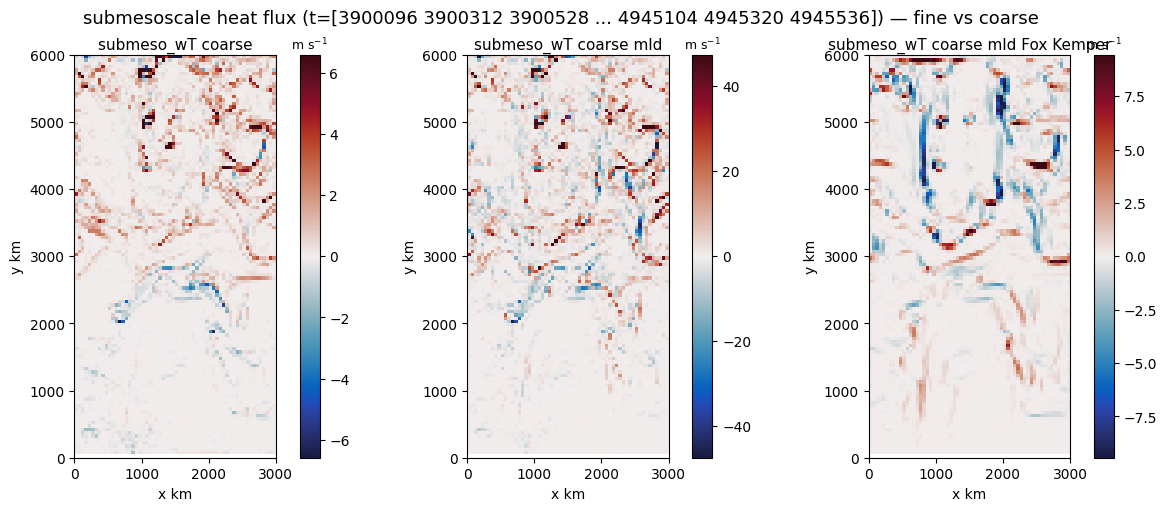

In [19]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import coarsen_UVWTS
import read_mitgcm
import build_coarse_grid
import numpy as np
from matplotlib import pyplot as plt
import cmocean.cm as cmo
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import wT
import xarray as xr
from MITgcmutils import mds
import mld_avg
import importlib
importlib.reload(wT)   # force reload
importlib.reload(read_mitgcm) 
importlib.reload(build_coarse_grid) 
#  MITgcm path
path_scratch = '/scratch/jczhang/'
path_MITgcm = 'MITgcm_5km/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
# time index
nStep1, nStep2, dS = 3900096, 4945536, 216
time_index = np.arange(nStep1, nStep2 + 1, dS, dtype=int)
num_data = time_index.size
print("Total data number is:", num_data)
# choose a vertical level
k = 0
box_i, box_j=10, 10
# get the grid variables and create the ds
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i)

# coordinate variable
XC = ds_fine["XC"].values
YC = ds_fine["YC"].values
XCc = ds_coarse["XC"].values
YCc = ds_coarse["YC"].values

# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

# load the data
submeso_wT_npy = np.load("./var/submeso_wT.npy")
print(submeso_wT_npy.shape)

W = read_mitgcm._ocean_var(grid_dir, "W", time_index[-1], ("k_l","j","i"))
W_coarse = coarsen_UVWTS.coarse_field("W", W, ds_fine, box_j, box_i)
T = read_mitgcm._ocean_var(grid_dir, "T", time_index[-1], ("k","j","i"))
T_coarse = coarsen_UVWTS.coarse_field("T", T, ds_fine, box_j, box_i)

ds_ocean = xr.Dataset(dict(W=W, T=T))
ds_ocean_c = xr.Dataset(dict(W=W_coarse, T=T_coarse))

submeso_wT_coarse = wT.submeso_vertical_heat_flux(ds_fine, ds_coarse, ds_ocean, ds_ocean_c, box_j = 10, box_i = 10,boundary_Z = "fill", to_wm2 = True)

#  mixed layer avergae
diagMXL = mds.rdmds(path_scratch + path_MITgcm + 'Diags/' +'DiagMXL_2d', time_index[-1])
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine, box_j, box_i)
submeso_wT_coarse_mld = mld_avg.mld_avg(submeso_wT_coarse, kpphbl_coarse, ds_coarse)

# div_coarse_mld[2403 + _ ,:,:]
fields = {
    # "submesoscale wT":  {"Z": strain_fine[k,:,:],    "units": r"m s$^{-1}$",    "kind": "signed", "cmap": cmo.balance, "X": XC/1e3, "Y": YC/1e3 },
    "submeso_wT coarse":  {"Z": submeso_wT_coarse[k,:,:],    "units": r"m s$^{-1}$",    "kind": "signed", "cmap": cmo.balance, "X": XCc[:,:]/1e3, "Y": YCc[:,:]/1e3},
    "submeso_wT coarse mld":  {"Z": submeso_wT_coarse_mld[:,:],  "units": r"m s$^{-1}$", "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3},
    "submeso_wT coarse mld Fox Kemper":  {"Z": submeso_wT_FK[:,:],  "units": r"m s$^{-1}$", "kind": "signed", "cmap": cmo.balance, "X": XCc/1e3, "Y": YCc/1e3},
}

# Compute norms/limits per field
for key, meta in fields.items():    # key is the variable name, meta is the dict contains the variables, units...
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        q = pos_limits(Z)
        meta["norm"] = Normalize(vmin=0.0, vmax=q)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(1, 3, figsize=(12, 5), constrained_layout=True, squeeze=False)
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    X = meta["X"]; Y = meta["Y"]; Z = meta["Z"]; 
    cmap = meta["cmap"]
    norm = meta["norm"]
    pc = ax.pcolormesh(X, Y, Z, shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)

fig.suptitle(f"submesoscale heat flux (t={time_index}) — fine vs coarse", fontsize=13)


# R2

In [8]:
import numpy as np

def r2_global(y_true, y_pred):
    """
    Global R² over all samples and pixels.
    y_true, y_pred: np.ndarray with same shape (N, H, W) or (N, 1, H, W)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    # remove singleton channel if present
    if y_true.ndim == 4 and y_true.shape[1] == 1:
        y_true = y_true[:, 0, ...]
        y_pred = y_pred[:, 0, ...]
    
    # mask NaNs (e.g. land)
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true_flat = y_true[mask]
    y_pred_flat = y_pred[mask]

    # standard R² = 1 - SSR / SST
    ss_res = np.sum((y_true_flat - y_pred_flat)**2)
    ss_tot = np.sum((y_true_flat - y_true_flat.mean())**2)

    return 1.0 - ss_res / ss_tot


def r2_per_image(y_true, y_pred):
    """
    R² for each image separately, plus their mean.
    Returns: r2_list (N,), r2_mean (scalar)
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    if y_true.ndim == 4 and y_true.shape[1] == 1:
        y_true = y_true[:, 0, ...]
        y_pred = y_pred[:, 0, ...]

    N = y_true.shape[0]
    r2_list = np.empty(N, dtype=float)

    for n in range(N):
        yt = y_true[n]
        yp = y_pred[n]

        mask = np.isfinite(yt) & np.isfinite(yp)
        yt_flat = yt[mask]
        yp_flat = yp[mask]

        ss_res = np.sum((yt_flat - yp_flat)**2)
        ss_tot = np.sum((yt_flat - yt_flat.mean())**2)

        r2_list[n] = 1.0 - ss_res / ss_tot

    return r2_list, float(r2_list.mean())

In [25]:
data = np.load("/scratch/jczhang/data_5km/var_6000/submeso_wT.npz")
y_true = data["data"][0:9,]
print(y_true.shape)

(9, 116, 58)


In [18]:
def _fit_z_norm_y(y_train):
    """
    y_train: (N, 1, H, W) or (N, H, W) or (N,)
    Returns scalar mu, sd (broadcastable).
    """
    EPS = 1e-12
    mu = y_train.mean()
    sd = y_train.std(ddof=1) + EPS
    return np.float32(mu), np.float32(sd)

def _apply_z_norm_y(y, mu, sd):
    return (y - mu) / sd
    
y_mu, y_sd = _fit_z_norm_y(y_true)
y_true = _apply_z_norm_y(y_true, y_mu, y_sd)

data_arr_mu, data_arr_sd = _fit_z_norm_y(data_arr)
data_arr = _apply_z_norm_y(data_arr, data_arr_mu, data_arr_sd)

In [13]:
R2_fk_global = r2_global(y_true, data_arr)

-0.9462417244687131


In [33]:
print(R2_fk_global)

-0.01614192723942498
